In [1]:
# 그래프 관련 import
import matplotlib.pyplot as plt
import matplotlib
matplotlib.rcParams['font.family'] = 'Malgun Gothic'
# matplotlib.rcParams['font.family'] = 'AppleGothic'
matplotlib.rcParams['axes.unicode_minus']=False

import pandas as pd
import numpy as np
from sklearn import svm,metrics
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neighbors import KNeighborsRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error       # 평균절대값오차 오차범위
from sklearn.model_selection import train_test_split  # 정규화 클래스
from sklearn.preprocessing import StandardScaler

In [2]:
# 다항회귀로 구현하시오.
# 1. 공부시간에 따른 점수 예측을 다항회귀로 구현하시오.

In [3]:
df = pd.read_csv('data/study.csv',sep='\t')
df[:2]

,our,score
0,0.5,10
1,1.2,8


In [4]:
data = df.iloc[:,:-1].values
label = df.iloc[:,1:].values

In [5]:
train_data,test_data, train_label, test_label = train_test_split(data,label)

In [6]:
train_poly = np.column_stack((train_data**2,train_data))
test_poly = np.column_stack((test_data**2,test_data))

In [7]:
# 데이터 학습
lr = LinearRegression()
# 선형회귀 
lr.fit(train_poly,train_label)
# 데이터 예측
predict = lr.predict(test_poly)
print('점수예측 : ',predict)

점수예측 :  [[ 23.75463126]
 [ 39.79528131]
 [ 60.07801334]
 [ 87.7691716 ]
 [104.77303392]]


In [8]:
score = lr.score(train_poly,train_label)
score2 = lr.score(test_poly,test_label)
print('학습데이터 예측 : ',score)
print('테스트데이터 예측 : ',score2)

학습데이터 예측 :  0.9464901158587381
테스트데이터 예측 :  0.9527337303339569


In [10]:
in_data = input('공부시간을 입력하세요.>> ')
in_data = float(in_data)
result = lr.predict([[in_data**2,in_data]])
print(f"공부시간에 따른 예측점수 : {result[0]:.2f} 점")

TypeError: unsupported format string passed to numpy.ndarray.__format__

In [ ]:
# 구간별 직선을 그리기 위해 범위 정수배열 생성
point = np.arange(1,10)

In [ ]:
# lr.coef_ : 다항회귀는 기울기가 2개 나옴, lr.intercept_ : y절편 
print(lr.coef_, lr.intercept_)

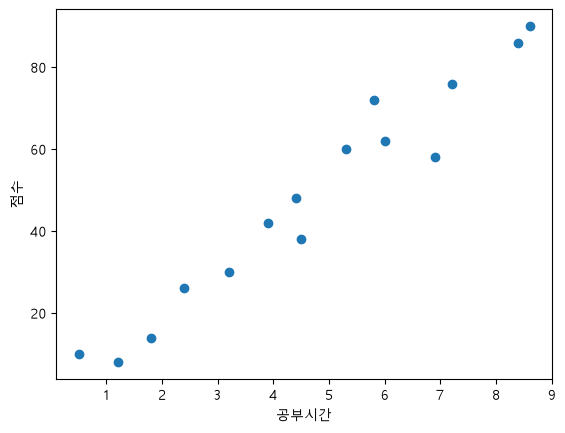

In [ ]:
# 산점도 그래프
plt.scatter(train_data, train_label)
plt.scatter(8, 85.72, marker='^')
plt.plot(point,lr.coef_[0]*point**2+lr.coef_[1]*point+lr.intercept_)
plt.xlabel('시간')
plt.ylabel('점수')
plt.show()